#### Week 10 - Computer Vision: see, detect, and map the built environment

In Week 8 we clustered the Florida images with a SOM; last week (Week 9) we **turned the clusters into labels
and trained classifiers** on them.
This week we (1) look *inside* the image the way a vision model does, (2) **detect and
count objects** in each photo, and (3) **map** those results across the cities.

Flow: recap Week 9 (with a backup) -> classify the whole picture -> detect objects ->
put it all on an interactive map.

##### > The data: your Florida images (Week 8) and your labels (Week 9)

This week works on the **same images** as Weeks 8 and 9, read from your Drive:
- **images** - `Colab Notebooks/ML_for_Architects/Week8/01_images/<perspective>/<city>/`, or the
  instructor's shared folder `Week8_shared_data` (as in Week 9). The *perspectives* are
  `streetview`, `satellite` and `archdaily`.
- **labels** - your Week 9 classes, `Colab Notebooks/ML_for_Architects/Week9/labels/<perspective>_labelled.csv`
  (for a perspective without them, last week's SOM clusters from the Week 8 CSVs are used).
- **coordinates** - the `lat` / `lon` columns of the same CSVs (the image files carry no GPS).

Everything this notebook writes goes into a new folder `Week10/`; the Week 8 and Week 9 files are only read.

Pick a case below. To use **your own** photos, drop them in a folder of subfolders and add
it to `CASES` (phone photos already carry EXIF GPS).

To use GPU:

- Runtime → Change runtime type
- Under Hardware accelerator, pick T4 GPU (not "None"/"CPU")
- Click Save

In [2]:
import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU -> Runtime > Change runtime type > GPU, then Runtime > Restart, and re-run.')

GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
# your course folder in Drive: this notebook writes its files into Week10/ (Weeks 8 and 9 are only read)
COURSE_DIR = '/content/drive/MyDrive/Colab Notebooks/ML_for_Architects'
os.makedirs(f'{COURSE_DIR}/Week10', exist_ok=True)
os.chdir(f'{COURSE_DIR}/Week10')
print('working folder:', os.getcwd())

working folder: /content/drive/MyDrive/Colab Notebooks/ML_for_Architects/Week10


In [5]:
# --- one-time installs (Colab); does nothing if already present ---
import importlib.util, subprocess, sys
for pkg, pip_name in [('open_clip', 'open_clip_torch'), ('ipywidgets', 'ipywidgets'),
                      ('minisom', 'minisom'), ('folium', 'folium')]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name])

import csv, math, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display
%matplotlib inline

# Drive is mounted above; COURSE_DIR (cell above) is your 'Colab Notebooks/ML_for_Architects' folder.

# ============ PREPARED CASES (edit paths if needed) ===============
CASES = {
    'florida (my Week 8)': f'{COURSE_DIR}/Week8/01_images',                          # your own Week 8 images
    'florida (shared Week 8)': '/content/drive/MyDrive/Week8_shared_data/01_images',  # the instructor's, as in Week 9
}
WEEK9_LABELS = f'{COURSE_DIR}/Week9/labels'      # your Week 9 classes: <perspective>_labelled.csv
# ===================================================================

MAX_IMAGES = 400        # cap per perspective (speed / memory safety belt)
SEED = 46
IMG_EXTS = {'.jpg', '.jpeg', '.png'}

def list_images(folder):
    # images in the folder and its sub-folders (Week 8 keeps one sub-folder per city; '_archive' is skipped)
    return sorted(p for p in Path(folder).rglob('*')
                  if p.is_file() and p.suffix.lower() in IMG_EXTS
                  and not any(part.startswith('_') for part in p.relative_to(folder).parts))

def _name_latlon(p):
    # files named 'lat_lon.jpg' -> (lat, lon)
    parts = Path(p).stem.split('_')
    try:
        if len(parts) == 2:
            return (float(parts[0]), float(parts[1]))
    except ValueError:
        pass
    return None

def _exif_latlon(p):
    # GPS baked into the photo (EXIF) -> (lat, lon)
    try:
        ex = Image.open(p)._getexif() or {}
        gps = ex.get(34853)          # GPSInfo tag
        if not gps:
            return None
        to_deg = lambda v: float(v[0]) + float(v[1]) / 60 + float(v[2]) / 3600
        lat, lon = to_deg(gps[2]), to_deg(gps[4])
        if gps.get(1) == 'S': lat = -lat
        if gps.get(3) == 'W': lon = -lon
        return (lat, lon)
    except Exception:
        return None

LATLON = {}     # filename -> (lat, lon) from the Week 8/9 CSVs (filled when the images are loaded below)

def get_latlon(p):
    # Florida images: coordinates from the Week 8/9 CSVs; own photos: the filename first, then EXIF
    return LATLON.get(Path(p).name) or _name_latlon(p) or _exif_latlon(p)

case = widgets.Dropdown(options=list(CASES), description='Case:',
                        value=next((k for k, v in CASES.items() if Path(v).exists()), list(CASES)[0]))
display(case)

Dropdown(description='Case:', options=('florida (my Week 8)', 'florida (shared Week 8)'), value='florida (my W…

#### 0. Pick - a case and a perspective

In [6]:
# PICK: which case + perspective (subfolder) to work on.
CASE_ROOT = Path(CASES[case.value])
assert CASE_ROOT.exists(), f'Folder not found: {CASE_ROOT.resolve()} -- fix its path in CASES.'
PERSPECTIVES = [d.name for d in sorted(CASE_ROOT.iterdir())
                if d.is_dir() and not d.name.startswith('_') and list_images(d)]
assert PERSPECTIVES, f'No image subfolders found under {CASE_ROOT}.'

perspective = widgets.Dropdown(options=PERSPECTIVES, description='Perspective:',
                               value='streetview' if 'streetview' in PERSPECTIVES else PERSPECTIVES[0])
print('Case:', case.value, '| perspectives:', PERSPECTIVES)
display(perspective)

Case: florida (my Week 8) | perspectives: ['archdaily', 'satellite', 'streetview']


Dropdown(description='Perspective:', index=2, options=('archdaily', 'satellite', 'streetview'), value='streetv…

In [7]:
# CLIP-embed the chosen perspective's images (cached per case+perspective).
try:
    _model
except NameError:
    import torch, open_clip
    _device = 'cuda' if torch.cuda.is_available() else 'cpu'
    _model, _, _preprocess = open_clip.create_model_and_transforms(
        'ViT-B-32', pretrained='laion2b_s34b_b79k')
    _model = _model.to(_device).eval()
    print('CLIP loaded on', _device)

# Last weeks' table for this perspective: your Week 9 labels, else the Week 8 CSVs (coordinates + SOM clusters)
import pandas as pd

def read_table(name):
    w9 = Path(WEEK9_LABELS) / f'{name}_labelled.csv'
    if w9.exists():
        return pd.read_csv(w9, dtype={'image_id': str}), str(w9)
    w8 = CASE_ROOT.parent / '02_features' / 'embeddings' / name
    if w8.is_dir() and list(w8.glob('*.csv')):
        return (pd.concat([pd.read_csv(f, dtype={'image_id': str}) for f in sorted(w8.glob('*.csv'))],
                          ignore_index=True), str(w8))
    return None, None                                     # e.g. your own photos: no table

TABLE, TABLE_SRC = read_table(perspective.value)
if TABLE is not None:
    TABLE['filename'] = [Path(r).name for r in TABLE.relpath]
    LATLON.update({f: (la, lo) for f, la, lo in zip(TABLE.filename, TABLE.lat, TABLE.lon) if pd.notna(la)})

def select_images(folder):
    fs = list_images(folder)
    if TABLE is not None and 'label' in TABLE:            # Week 9: only the images that got a label
        labelled = set(TABLE.loc[TABLE.label.notna(), 'filename'])
        fs = [p for p in fs if p.name in labelled]
    if len(fs) > MAX_IMAGES:                               # a random sample over all cities (not the first folders)
        rng = np.random.default_rng(SEED)
        fs = sorted(fs[i] for i in rng.choice(len(fs), MAX_IMAGES, replace=False))
    return fs

_cache = globals().get('_cache', {})
def embed_perspective(root, name):
    key = (str(root), name)
    if key in _cache:
        return _cache[key]
    import torch
    fs = select_images(root / name)
    feats, keep = [], []
    for i in range(0, len(fs), 64):
        ims, ok = [], []
        for p in fs[i:i + 64]:
            try:
                ims.append(_preprocess(Image.open(p).convert('RGB'))); ok.append(p)
            except Exception:
                pass
        if not ims:
            continue
        with torch.no_grad():
            f = _model.encode_image(torch.stack(ims).to(_device))
            f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu().numpy()); keep += ok
    Xe = np.concatenate(feats).astype(np.float32)
    _cache[key] = (keep, Xe)
    return keep, Xe

files, X = embed_perspective(CASE_ROOT, perspective.value)
ll = [get_latlon(p) for p in files]
print(f'{perspective.value}: {len(files)} images embedded -> {X.shape[1]}-d features; '
      f'{sum(1 for c in ll if c)} geotagged')

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded on cuda
streetview: 400 images embedded -> 512-d features; 400 geotagged


#### Recap Week 9 - your labels (with a backup)

We need last week's **labels** to keep going. This cell uses your Week 9 classes
(`Week9/labels/<perspective>_labelled.csv`) if they are there, otherwise last week's SOM clusters
from the Week 8 CSVs; if neither exists (e.g. your own photos), it **rebuilds** the typologies
from scratch (SOM -> group -> auto-name) so you are never stuck. Either way you leave this cell with a label per image.

In [9]:
# Load your Week 9 labels (or the Week 8 SOM clusters) if present; otherwise regenerate them (backup).
y = None
if TABLE is not None and ('label' in TABLE or 'som_cluster' in TABLE):
    col = 'label' if 'label' in TABLE else 'som_cluster'
    by_name = {f: (l if col == 'label' else f'cluster {int(l)}')
               for f, l in zip(TABLE.filename, TABLE[col]) if pd.notna(l)}
    got = [by_name.get(Path(p).name) for p in files]
    if all(g is not None for g in got):
        y = np.array(got)
        print(f'loaded labels from {TABLE_SRC} (column {col!r})')

if y is None:
    print('no labels for these images -- rebuilding typologies from scratch (backup)')
    from minisom import MiniSom
    from sklearn.cluster import KMeans
    m = max(3, min(8, int(round((len(X) / 6) ** 0.5))))
    som = MiniSom(m, m, X.shape[1], sigma=1.0, learning_rate=0.5,
                  activation_distance='cosine', random_seed=SEED)
    som.random_weights_init(X); som.train_random(X, 1500)
    win = np.array([som.winner(x) for x in X])
    Wflat = som.get_weights().reshape(m * m, X.shape[1])
    K = max(2, min(6, m))
    node_group = KMeans(K, n_init=10, random_state=SEED).fit_predict(Wflat)
    clust = node_group[win[:, 0] * m + win[:, 1]]
    y = np.array([f'type_{c}' for c in clust])

classes, counts = np.unique(y, return_counts=True)
print('classes:', dict(zip(classes.tolist(), counts.tolist())))

loaded labels from /content/drive/MyDrive/Colab Notebooks/ML_for_Architects/Week9/labels/streetview_labelled.csv (column 'label')
classes: {'cluster 0': 189, 'cluster 1': 172, 'cluster 2': 39}


### Section 1 - Classify the whole picture

A classic computer-vision task: show the model an image, it returns **one label** for the
whole thing. Last week's classifier already does this on top of **CLIP** - a large vision
model that was *pretrained* on millions of images. Reusing it is called **transfer
learning**. Below we (a) run that whole-image classifier, (b) train a small CNN of your
own, and (c) look *inside* that trained CNN to see which pixels it leaned on.

whole-image test accuracy: 0.75


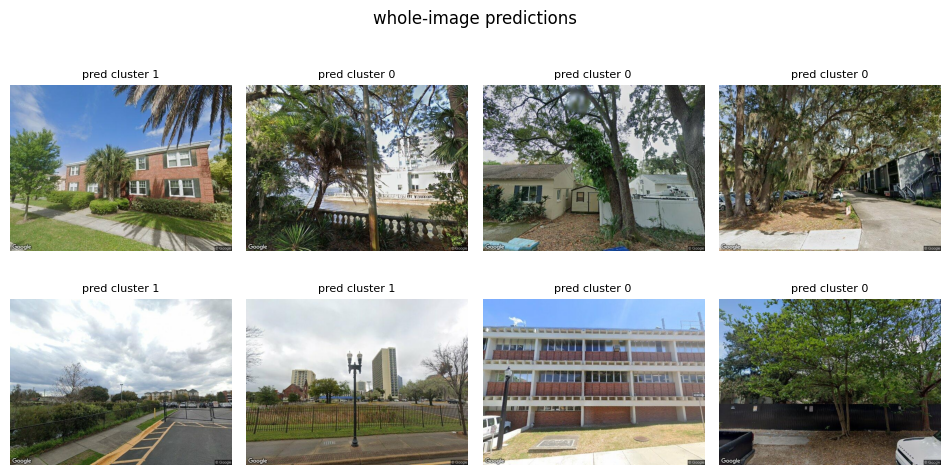

In [10]:
# (a) Whole-image classification: train a light head on the CLIP features, read a score.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

_, cnts = np.unique(y, return_counts=True)
strat = y if cnts.min() >= 2 else None
Xtr, Xte, ytr, yte, itr, ite = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, random_state=SEED, stratify=strat)
clf = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print(f'whole-image test accuracy: {clf.score(Xte, yte):.2f}')

# a small gallery of predictions on held-out images
show = ite[:8]; cols = 4; rows = math.ceil(len(show) / cols)
plt.figure(figsize=(2.4 * cols, 2.6 * rows))
for j, gi in enumerate(show):
    plt.subplot(rows, cols, j + 1)
    plt.imshow(Image.open(files[gi]).convert('RGB')); plt.axis('off')
    plt.title(f'pred {clf.predict(X[gi:gi+1])[0]}', fontsize=8)
plt.suptitle('whole-image predictions'); plt.tight_layout(); plt.show()

#### (b) Train your own small CNN

Train a tiny CNN **from the pixels** on your labeled images - the model your slides
describe. It is slower and can **overfit** on small data (a teaching point in itself). We
look *inside* this trained CNN in the next cell, so keep `TRAIN_CNN = True` to see it.

In [11]:
TRAIN_CNN = True        # train a small CNN on the raw pixels (needed by the Grad-CAM below)

if TRAIN_CNN:
    import torch, torch.nn as nn
    from torchvision import transforms
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder(); yi = torch.tensor(le.fit_transform(y))
    tf2 = transforms.Compose([transforms.Resize((64, 64)), transforms.ToTensor()])
    imgs = torch.stack([tf2(Image.open(p).convert('RGB')) for p in files])
    n = len(imgs); idx = torch.randperm(n); cut = int(0.75 * n)
    tr, te = idx[:cut], idx[cut:]
    net = nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 16 * 16, 64), nn.ReLU(),
        nn.Linear(64, len(le.classes_)))
    opt = torch.optim.Adam(net.parameters(), 1e-3); lossf = nn.CrossEntropyLoss()
    for ep in range(100):
        net.train(); opt.zero_grad()
        loss = lossf(net(imgs[tr]), yi[tr]); loss.backward(); opt.step()
    net.eval()
    acc = (net(imgs[te]).argmax(1) == yi[te]).float().mean().item()
    print(f'tiny-CNN test accuracy: {acc:.2f}  (compare with the CLIP head above)')
else:
    print('TRAIN_CNN is off -- skipping (the Grad-CAM below needs it).')

tiny-CNN test accuracy: 0.73  (compare with the CLIP head above)


#### (c) How your CNN "sees" - a look inside

A CNN builds its answer from **local patterns** (edges -> textures -> parts). Here we look
inside **the CNN you just trained**: we run it on one held-out image and draw a **heat map**
(Grad-CAM) of the pixels it leaned on to pick its class - the intuition from your slides,
made visible on your own model.

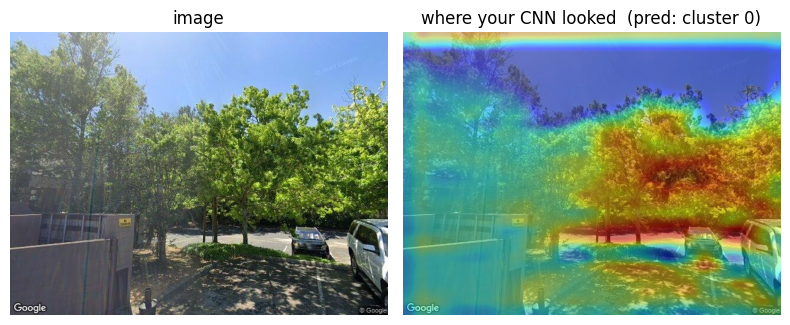

In [12]:
# Grad-CAM on YOUR trained CNN: which pixels drove its decision?
import torch
assert 'net' in globals(), 'Train the CNN first: set TRAIN_CNN = True in the cell above and run it.'

net.eval()
last_conv = net[3]                       # the last Conv2d layer in your small CNN
acts, grads = {}, {}
h1 = last_conv.register_forward_hook(lambda m, i, o: acts.__setitem__('v', o.detach()))
h2 = last_conv.register_full_backward_hook(lambda m, gi, go: grads.__setitem__('v', go[0].detach()))

pick = int(te[0]) if len(te) else 0      # a held-out image
out = net(imgs[pick:pick + 1]); cls = int(out.argmax(1))
net.zero_grad(); out[0, cls].backward()
h1.remove(); h2.remove()

w = grads['v'].mean((2, 3), keepdim=True)                  # importance of each feature map
cam = torch.relu((w * acts['v']).sum(1))[0]                # weighted sum -> heat map
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-6)

pil = Image.open(files[pick]).convert('RGB')
heat = np.array(Image.fromarray((cam.numpy() * 255).astype('uint8')).resize(pil.size))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(pil); ax[0].set_title('image'); ax[0].axis('off')
ax[1].imshow(pil); ax[1].imshow(heat, cmap='jet', alpha=0.45)
ax[1].set_title(f'where your CNN looked  (pred: {le.classes_[cls]})'); ax[1].axis('off')
plt.tight_layout(); plt.show()

### Section 2 - Detect objects in each photo

Whole-image classification gives one label per photo. **Object detection** goes further:
it finds and **counts** the things inside each image (cars, trees, windows, people...).
Two ways to do it - pick whichever you like; both make the **same CSV**
(`latitude, longitude, datetime, filename, object_name, object_quantity`).

#### Option A (easiest) - the GulfSouth web tool

No code. Open the tool, drag in your images, download the CSV:
**https://guozifeng91.github.io/GulfSouth/objextract/image_extract.html**
It runs a pretrained detector (SSD MobileNet v2, OpenImages) in your browser and reads the
GPS from each photo's EXIF. *Works with your own phone photos* (they carry EXIF GPS); the Florida
images of Week 8 have no GPS inside the file, so for them use Option B, which takes the coordinates
from the Week 8/9 CSVs. Save the downloaded CSV in your `Week10` folder, then load it below.

https://huggingface.co/spaces/Mobinaaaa/building-counter

In [13]:
# Load a CSV produced by the GulfSouth web tool (or any file with the same columns).
# Default: the CSV that Option B wrote for this perspective (in your Week10 folder), then a
# file you downloaded into your Week10 folder.
DETECTION_CSV = Path(f'{perspective.value}_detection_output.csv')
if not Path(DETECTION_CSV).exists():
    DETECTION_CSV = Path('detection_output.csv')      # <- or point this at your download

det_rows = []
if Path(DETECTION_CSV).exists():
    det_rows = [r for r in csv.DictReader(open(DETECTION_CSV, encoding='utf-8'))
                if r.get('object_name')]
    print(f'loaded {len(det_rows)} detections from {DETECTION_CSV}')
else:
    print('no CSV yet -- run the web tool, or use Option B below.')

no CSV yet -- run the web tool, or use Option B below.


#### Option B - detect inside this notebook

Runs a pretrained detector (YOLO) right here and writes the **same CSV**. Use this for the
Florida images (the coordinates come from the Week 8/9 CSVs) or when you want everything in one place.

In [14]:
# In-notebook detection with a pretrained YOLO model -> same CSV schema.
RUN_DETECTOR = True        # flip to True (first run downloads the model)

if RUN_DETECTOR:
    if importlib.util.find_spec('ultralytics') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    from ultralytics import YOLO
    yolo = YOLO('yolov8n.pt')
    cols = ['latitude', 'longitude', 'datetime', 'filename', 'object_name', 'object_quantity']
    out = Path(f'{perspective.value}_detection_output.csv')     # in your Week10 folder
    det_rows = []
    for p in files:
        res = yolo(str(p), verbose=False)[0]
        counts = {}
        for c in res.boxes.cls.tolist():
            nm = res.names[int(c)]
            counts[nm] = counts.get(nm, 0) + 1
        geo = get_latlon(p) or ('', '')
        for obj, q in counts.items():
            det_rows.append({'latitude': geo[0], 'longitude': geo[1], 'datetime': '',
                             'filename': Path(p).name, 'object_name': obj, 'object_quantity': q})
    with open(out, 'w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(det_rows)
    print(f'wrote {len(det_rows)} detections -> {out}')
else:
    print('RUN_DETECTOR is off -- using the CSV from Option A (if loaded).')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
wrote 352 detections -> streetview_detection_output.csv


### Section 3 - Put it on the map

Every result carries a **lat/lon**, so we can place it geographically - an automated
**site inventory**. Below: an interactive map of the detected objects, colored by type,
with a density heat layer.

In [16]:
# Interactive map (folium): detected objects, colored by type, plus a density heatmap.
import folium
from folium.plugins import HeatMap

pts = []
for r in det_rows:
    try:
        pts.append((float(r['latitude']), float(r['longitude']),
                    r['object_name'], int(float(r['object_quantity']))))
    except (ValueError, TypeError):
        pass
assert pts, 'No geotagged detections to map -- load a CSV (Option A) or run Option B.'

clat = np.mean([p[0] for p in pts]); clon = np.mean([p[1] for p in pts])
palette = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue', 'black']
kinds = sorted({p[2] for p in pts})
color = {k: palette[i % len(palette)] for i, k in enumerate(kinds)}

fmap = folium.Map(location=[clat, clon], zoom_start=16, tiles=None)
folium.TileLayer('CartoDB positron', name='light map').add_to(fmap)
folium.TileLayer(tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                 attr='Esri World Imagery', name='satellite').add_to(fmap)
fmap.fit_bounds([[min(p[0] for p in pts), min(p[1] for p in pts)],
                 [max(p[0] for p in pts), max(p[1] for p in pts)]])     # the Florida images span several cities
for lat, lon, obj, q in pts:
    folium.CircleMarker([lat, lon], radius=3 + q, color=color[obj], fill=True,
                        fill_opacity=0.7, popup=f'{obj} x{q}').add_to(fmap)
HeatMap([[lat, lon] for lat, lon, _, _ in pts]).add_to(
    folium.FeatureGroup(name='density').add_to(fmap))
folium.LayerControl().add_to(fmap)
fmap

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


#### (Advanced) ArcGIS Online

Prefer ArcGIS? Export a clean CSV and upload it to ArcGIS Online (Map Viewer -> Add ->
From file), or use the `arcgis` Python API. The CSV already has `latitude`/`longitude`,
so ArcGIS maps it directly.

In [ ]:
# Export the detections for ArcGIS Online upload.
arc_out = 'detections_for_arcgis.csv'
cols = ['latitude', 'longitude', 'datetime', 'filename', 'object_name', 'object_quantity']
with open(arc_out, 'w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader()
    for r in det_rows:
        w.writerow({k: r.get(k, '') for k in cols})
print('wrote', arc_out, '-- upload this to ArcGIS Online, or feed the arcgis Python API.')

You just ran a full **computer-vision** pass on the same project: classified whole images,
looked *inside* a CNN, **detected and counted** objects, and mapped them into a site
inventory. Next: the **generative** week, where we turn these readings into new design
variations.